# LogiExpress: Sistema de gestión de rutas de entrega

**Proyecto final — Estructuras de datos (Universidad EAN)**

**Autor:** _Samuel Mariño - Grupo 1_ *(desarrollo individual)*

---

## Contenido

1. Introducción y descripción del problema
2. Modelo de datos: clase `Grafo`
3. Datos de ejemplo: red logística de Bogotá
4. Algoritmo de Dijkstra
5. Algoritmo de Floyd-Warshall
6. Visualización
7. Interfaz de consola
8. Demostración

## 1. Introducción y descripción del problema

**LogiExpress** es una startup de entrega de paquetes que opera en Bogotá. Sus vehículos salen de
**bodegas** y deben llegar a distintos **barrios** de la ciudad. Para reducir tiempos y costos,
la empresa necesita una herramienta que calcule y recomiende las rutas de entrega más eficientes.

### Modelado como grafo

| Elemento del problema | Elemento del grafo |
|---|---|
| Bodega o barrio | **Vértice** (nodo) |
| Vía que conecta dos ubicaciones | **Arista** |
| Tiempo de recorrido (minutos) | **Peso** de la arista |

El grafo es **no dirigido** (las vías se recorren en ambos sentidos) y **ponderado** con pesos
**no negativos** (un tiempo de viaje nunca es negativo).

### Algoritmos

- **Dijkstra:** ruta más corta desde **un origen** hacia **todos los destinos**. Ideal cuando un
  vehículo sale de una bodega y hay que planear las entregas desde ese punto.
- **Floyd-Warshall:** rutas más cortas entre **todos los pares** de ubicaciones. Ideal para tener
  precalculada una tabla completa de tiempos y, por ejemplo, decidir qué bodega debe despachar
  un pedido.

Ambos algoritmos se implementan **a mano**. `networkx` y `matplotlib` se usan **solo para dibujar**.

## 2. Modelo de datos: clase `Grafo`

Se usa una **lista de adyacencia** implementada con diccionarios:

```
adyacencia = {
    "Chapinero":   {"Teusaquillo": 9, "Usaquén": 18, ...},
    "Teusaquillo": {"Chapinero": 9, ...},
}
```


Cada ubicación guarda además un **tipo** (`"bodega"` o `"barrio"`) para la visualización y las
recomendaciones.

In [19]:
# Librerías
import heapq                     # Cola de prioridad (min-heap) para Dijkstra
import math                      # math.inf representa "sin ruta conocida"
import unicodedata               # Normalizar tildes al leer nombres desde la consola

import matplotlib.pyplot as plt  # Visualización
import networkx as nx            # Solo para DIBUJAR el grafo (no para calcular rutas)
from IPython.display import display  # Mostrar figuras de inmediato dentro del menú

# Constantes de visualización (paleta validada para daltonismo)
COLOR_BARRIO = "#2a78d6"   # azul
COLOR_BODEGA = "#eb6834"   # naranja
COLOR_RUTA = "#1baf7a"     # verde agua: ruta resaltada
COLOR_ARISTA = "#c3c2b7"   # gris: vías no resaltadas
COLOR_TEXTO = "#0b0b0b"

In [20]:
class Grafo:
    """Grafo ponderado representado con lista de adyacencia.

    Vértices = ubicaciones (bodegas y barrios).
    Aristas  = vías entre ubicaciones, con peso = tiempo en minutos.

    Memoria: O(V + E).
    """

    TIPOS_VALIDOS = ("bodega", "barrio")

    def __init__(self, dirigido=False):
        self.dirigido = dirigido
        self.adyacencia = {}   # {ubicacion: {vecino: peso}}
        self.tipos = {}        # {ubicacion: "bodega" | "barrio"}

    # ---------------- Construcción ----------------

    def agregar_ubicacion(self, nombre, tipo="barrio"):
        """Agrega un vértice. O(1). Si ya existe, solo actualiza su tipo."""
        if not isinstance(nombre, str) or not nombre.strip():
            raise ValueError("El nombre de la ubicación no puede estar vacío.")
        if tipo not in self.TIPOS_VALIDOS:
            raise ValueError(f"Tipo inválido '{tipo}'. Use uno de: {self.TIPOS_VALIDOS}.")  
        self.adyacencia.setdefault(nombre, {})
        self.tipos[nombre] = tipo

    def agregar_ruta(self, origen, destino, peso):
        """Agrega una arista con su peso. O(1).

        Se rechazan pesos negativos porque Dijkstra solo es correcto con
        pesos >= 0 (y un tiempo de viaje negativo no tiene sentido).
        Si alguna ubicación no existe, se crea como barrio.
        """
        self._validar_peso(peso)
        if origen == destino:
            raise ValueError(f"Una ruta no puede ir de '{origen}' a sí misma.")
        for nodo in (origen, destino):
            if nodo not in self.adyacencia:
                self.agregar_ubicacion(nodo)
        self.adyacencia[origen][destino] = peso
        if not self.dirigido:
            self.adyacencia[destino][origen] = peso

    @staticmethod
    def _validar_peso(peso):
        if isinstance(peso, bool) or not isinstance(peso, (int, float)) or math.isnan(peso):
            raise ValueError(f"El peso debe ser un número, se recibió: {peso!r}.")
        if peso < 0:
            raise ValueError(
                f"Peso negativo no permitido ({peso}). "
                "Los tiempos de viaje deben ser >= 0."
            )

    # ---------------- Consultas ----------------

    def existe(self, nombre):
        return nombre in self.adyacencia

    def validar_ubicacion(self, nombre):
        """Lanza un error claro si la ubicación no está en el grafo."""
        if not self.existe(nombre):
            raise KeyError(f"La ubicación '{nombre}' no existe en la red.")

    def ubicaciones(self):
        """Lista de vértices en orden de inserción."""
        return list(self.adyacencia)

    def vecinos(self, nombre):
        """Diccionario {vecino: peso} de una ubicación. O(1)."""
        self.validar_ubicacion(nombre)
        return self.adyacencia[nombre]

    def peso(self, origen, destino):
        return self.adyacencia[origen][destino]

    def tipo(self, nombre):
        return self.tipos[nombre]

    def bodegas(self):
        return [n for n in self.adyacencia if self.tipos[n] == "bodega"]

    def rutas(self):
        """Lista de aristas (origen, destino, peso), sin duplicar en grafos no dirigidos. O(V + E)."""
        resultado, vistas = [], set()
        for origen, vecinos in self.adyacencia.items():
            for destino, peso in vecinos.items():
                clave = (origen, destino) if self.dirigido else frozenset((origen, destino))
                if clave not in vistas:
                    vistas.add(clave)
                    resultado.append((origen, destino, peso))
        return resultado

    def __len__(self):
        return len(self.adyacencia)

    def __repr__(self):
        tipo = "dirigido" if self.dirigido else "no dirigido"
        return f"Grafo({tipo}, {len(self)} ubicaciones, {len(self.rutas())} rutas)"

## 3. Datos de ejemplo: red logística de Bogotá

Red con **3 bodegas** y **11 barrios/localidades** de Bogotá. Los pesos son **tiempos aproximados
en minutos** en hora valle. Las posiciones `(x, y)` son coordenadas aproximadas (oeste→este,
sur→norte) usadas solo para dibujar el mapa.

In [21]:
# (nombre, tipo, posición aproximada en el mapa)
UBICACIONES_BOGOTA = [
    ("Bodega Fontibón",      "bodega", (0.6, 5.2)),
    ("Bodega Puente Aranda", "bodega", (3.6, 3.6)),
    ("Bodega Toberín",       "bodega", (6.6, 11.0)),
    ("Suba",                 "barrio", (2.2, 9.3)),
    ("Usaquén",              "barrio", (7.2, 9.4)),
    ("Engativá",             "barrio", (1.4, 7.2)),
    ("Barrios Unidos",       "barrio", (4.6, 7.4)),
    ("Chapinero",            "barrio", (7.0, 6.9)),
    ("Teusaquillo",          "barrio", (5.0, 5.6)),
    ("La Candelaria",        "barrio", (7.0, 4.2)),
    ("Kennedy",              "barrio", (1.6, 2.6)),
    ("Bosa",                 "barrio", (0.4, 0.6)),
    ("Tunjuelito",           "barrio", (4.2, 1.0)),
    ("San Cristóbal",        "barrio", (7.4, 2.0)),
]

# (origen, destino, minutos)
RUTAS_BOGOTA = [
    ("Bodega Toberín", "Usaquén", 12),
    ("Bodega Toberín", "Suba", 28),
    ("Suba", "Usaquén", 25),
    ("Suba", "Engativá", 20),
    ("Suba", "Barrios Unidos", 22),
    ("Usaquén", "Chapinero", 18),
    ("Usaquén", "Barrios Unidos", 20),
    ("Engativá", "Barrios Unidos", 18),
    ("Engativá", "Bodega Fontibón", 15),
    ("Barrios Unidos", "Chapinero", 12),
    ("Barrios Unidos", "Teusaquillo", 10),
    ("Chapinero", "Teusaquillo", 9),
    ("Chapinero", "La Candelaria", 15),
    ("Bodega Fontibón", "Teusaquillo", 22),
    ("Bodega Fontibón", "Bodega Puente Aranda", 17),
    ("Bodega Fontibón", "Kennedy", 16),
    ("Teusaquillo", "La Candelaria", 11),
    ("Teusaquillo", "Bodega Puente Aranda", 14),
    ("Bodega Puente Aranda", "La Candelaria", 16),
    ("Bodega Puente Aranda", "Kennedy", 13),
    ("Bodega Puente Aranda", "Tunjuelito", 18),
    ("Kennedy", "Bosa", 14),
    ("Kennedy", "Tunjuelito", 15),
    ("Bosa", "Tunjuelito", 17),
    ("La Candelaria", "San Cristóbal", 14),
    ("Tunjuelito", "San Cristóbal", 20),
]


def crear_red_bogota():
    """Construye el grafo de ejemplo y devuelve (grafo, posiciones)."""
    grafo = Grafo(dirigido=False)
    posiciones = {}
    for nombre, tipo, posicion in UBICACIONES_BOGOTA:
        grafo.agregar_ubicacion(nombre, tipo)
        posiciones[nombre] = posicion
    for origen, destino, minutos in RUTAS_BOGOTA:
        grafo.agregar_ruta(origen, destino, minutos)
    return grafo, posiciones


red, POSICIONES = crear_red_bogota()
print(red)
print("Bodegas:", ", ".join(red.bodegas()))

Grafo(no dirigido, 14 ubicaciones, 26 rutas)
Bodegas: Bodega Fontibón, Bodega Puente Aranda, Bodega Toberín


## 4. Algoritmo de Dijkstra

**Idea (algoritmo voraz):** mantener la mejor distancia conocida a cada nodo. En cada paso se toma
de la cola de prioridad el nodo **no visitado más cercano al origen**; como no hay pesos negativos,
esa distancia ya es definitiva. Luego se **relajan** sus aristas: si pasar por él mejora la distancia
a un vecino, se actualiza y se guarda el **predecesor** para reconstruir el camino.

**Complejidad** (con min-heap `heapq`):

- Tiempo: **O((V + E) log V)** — cada arista puede insertar en el heap (O(log V)).
- Espacio: **O(V + E)**.

**Requisito:** pesos no negativos (lo garantiza la clase `Grafo`).

In [22]:
def dijkstra(grafo, origen):
    """Distancias mínimas desde `origen` a TODAS las ubicaciones.

    Devuelve (distancias, predecesores):
      - distancias[n]  = minutos mínimos desde origen hasta n (math.inf si no hay ruta)
      - predecesores[n] = nodo anterior a n en la ruta óptima (None para origen o inalcanzables)

    Complejidad: O((V + E) log V) en tiempo, O(V) de espacio extra.
    """
    grafo.validar_ubicacion(origen)

    distancias = {nodo: math.inf for nodo in grafo.ubicaciones()}
    predecesores = {nodo: None for nodo in grafo.ubicaciones()}
    distancias[origen] = 0

    cola = [(0, origen)]          # (distancia acumulada, nodo)
    visitados = set()

    while cola:
        distancia_actual, nodo = heapq.heappop(cola)

        # Un nodo puede estar varias veces en el heap; solo vale la primera (la menor).
        if nodo in visitados:
            continue
        visitados.add(nodo)

        # Relajación de aristas
        for vecino, peso in grafo.vecinos(nodo).items():
            nueva_distancia = distancia_actual + peso
            if nueva_distancia < distancias[vecino]:
                distancias[vecino] = nueva_distancia
                predecesores[vecino] = nodo
                heapq.heappush(cola, (nueva_distancia, vecino))

    return distancias, predecesores


def reconstruir_camino_dijkstra(predecesores, origen, destino):
    """Recorre los predecesores desde el destino hasta el origen. O(V).

    Devuelve la lista de nodos [origen, ..., destino] o [] si no hay ruta.
    """
    if origen == destino:
        return [origen]
    if predecesores[destino] is None:
        return []
    camino = [destino]
    while camino[-1] != origen:
        camino.append(predecesores[camino[-1]])
    camino.reverse()
    return camino


def ruta_mas_corta(grafo, origen, destino):
    """Ruta óptima origen→destino con Dijkstra. Devuelve (camino, minutos).

    Lanza ValueError si no existe ninguna ruta entre ambos puntos.
    """
    grafo.validar_ubicacion(destino)
    distancias, predecesores = dijkstra(grafo, origen)
    if distancias[destino] == math.inf:
        raise ValueError(f"No existe ninguna ruta entre '{origen}' y '{destino}'.")
    return reconstruir_camino_dijkstra(predecesores, origen, destino), distancias[destino]


def rutas_desde_origen(grafo, origen):
    """Todas las rutas óptimas desde un origen (un solo Dijkstra).

    Devuelve {destino: (camino, minutos)}; camino = [] si el destino es inalcanzable.
    """
    distancias, predecesores = dijkstra(grafo, origen)
    return {
        destino: (reconstruir_camino_dijkstra(predecesores, origen, destino), distancias[destino])
        for destino in grafo.ubicaciones()
    }

## 5. Algoritmo de Floyd-Warshall

**Idea (programación dinámica):** `dist[i][j]` es el mejor tiempo conocido de `i` a `j`. Para cada
nodo intermedio `k` se pregunta: *¿es más rápido ir de `i` a `j` pasando por `k`?*

```
si dist[i][k] + dist[k][j] < dist[i][j]:
    dist[i][j]      = dist[i][k] + dist[k][j]
    siguiente[i][j] = siguiente[i][k]
```

La matriz **`siguiente[i][j]`** guarda el primer salto desde `i` en la ruta óptima hacia `j`, lo que
permite reconstruir cualquier camino sin recalcular.

**Complejidad:**

- Tiempo: **O(V³)** — tres ciclos anidados sobre los vértices.
- Espacio: **O(V²)** — matrices `dist` y `siguiente`.

**Dijkstra vs. Floyd-Warshall:** ejecutar Dijkstra desde cada nodo cuesta O(V·(V+E) log V), mejor en
grafos muy dispersos; Floyd-Warshall es más simple, admite pesos negativos (sin ciclos negativos) y
es muy eficiente para redes pequeñas o medianas como esta.

In [23]:
def floyd_warshall(grafo):
    """Distancias mínimas entre TODOS los pares de ubicaciones.

    Devuelve (distancias, siguiente), ambas como diccionario de diccionarios:
      - distancias[i][j] = minutos mínimos de i a j (math.inf si no hay ruta)
      - siguiente[i][j]  = primer salto desde i hacia j (None si no hay ruta)

    Complejidad: O(V³) en tiempo, O(V²) en espacio.
    """
    nodos = grafo.ubicaciones()

    # 1. Inicialización: 0 en la diagonal, peso directo si hay arista, infinito en otro caso.
    distancias = {i: {j: math.inf for j in nodos} for i in nodos}
    siguiente = {i: {j: None for j in nodos} for i in nodos}
    for i in nodos:
        distancias[i][i] = 0
        siguiente[i][i] = i
        for j, peso in grafo.vecinos(i).items():
            distancias[i][j] = peso
            siguiente[i][j] = j

    # 2. Programación dinámica: permitir a k como nodo intermedio.
    for k in nodos:
        for i in nodos:
            if distancias[i][k] == math.inf:
                continue  # Poda: si i no llega a k, k no puede mejorar ninguna ruta desde i.
            for j in nodos:
                via_k = distancias[i][k] + distancias[k][j]
                if via_k < distancias[i][j]:
                    distancias[i][j] = via_k
                    siguiente[i][j] = siguiente[i][k]

    # 3. Un valor negativo en la diagonal indica un ciclo negativo (rutas sin mínimo).
    if any(distancias[n][n] < 0 for n in nodos):
        raise ValueError("El grafo contiene un ciclo de peso negativo.")

    return distancias, siguiente


def reconstruir_camino_floyd(siguiente, origen, destino):
    """Sigue la matriz `siguiente` desde origen hasta destino. O(V).

    Devuelve [origen, ..., destino] o [] si no hay ruta.
    """
    if siguiente[origen][destino] is None:
        return []
    camino = [origen]
    while camino[-1] != destino:
        camino.append(siguiente[camino[-1]][destino])
    return camino

### Recomendación de bodega de despacho

Con la matriz de Floyd-Warshall ya calculada, elegir la mejor bodega para un pedido es una consulta
**O(B)** (B = número de bodegas): basta comparar `dist[bodega][destino]`.

In [ ]:
def recomendar_bodega(grafo, destino, distancias_todos=None):
    """Bodegas ordenadas de la más rápida a la más lenta para llegar a `destino`.

    Reutiliza la matriz de Floyd-Warshall si se pasa ya calculada.
    Devuelve una lista [(bodega, minutos), ...].
    """
    grafo.validar_ubicacion(destino)
    if not grafo.bodegas():
        raise ValueError("La red no tiene bodegas registradas.")
    if distancias_todos is None:
        distancias_todos, _ = floyd_warshall(grafo)
    opciones = [(bodega, distancias_todos[bodega][destino]) for bodega in grafo.bodegas()]
    return sorted(opciones, key=lambda par: par[1])

## 6. Visualización

Funciones separadas de los algoritmos: reciben resultados ya calculados y solo los presentan.

- **Texto:** detalle de una ruta, tabla de rutas desde un origen y matriz de todos los pares.
- **Gráficos:** red completa, ruta resaltada, árbol de rutas desde un origen y mapa de calor de la matriz.

In [25]:
# ---------------- Presentación en texto ----------------

def formatear_minutos(minutos):
    return "sin ruta" if minutos == math.inf else f"{minutos:g} min"


def formatear_camino(camino):
    return " → ".join(camino) if camino else "(sin ruta)"


def mostrar_ruta(grafo, camino, minutos):
    """Recomendación detallada: ruta, tiempo total y tramo por tramo."""
    print(f"Ruta recomendada: {formatear_camino(camino)}")
    print(f"Tiempo total:     {formatear_minutos(minutos)}  ({len(camino) - 1} tramos)")
    acumulado = 0
    for paso, (a, b) in enumerate(zip(camino, camino[1:]), start=1):
        acumulado += grafo.peso(a, b)
        print(f"  {paso}. {a:<22} → {b:<22} {grafo.peso(a, b):>4g} min   (acumulado {acumulado:g} min)")


def mostrar_tabla_desde_origen(origen, rutas):
    """Tabla destino | tiempo | ruta, ordenada del destino más cercano al más lejano."""
    print(f"Rutas más cortas desde: {origen}\n")
    print(f"{'Destino':<22} {'Tiempo':>9}   Ruta")
    print("-" * 90)
    for destino, (camino, minutos) in sorted(rutas.items(), key=lambda item: item[1][1]):
        if destino != origen:
            print(f"{destino:<22} {formatear_minutos(minutos):>9}   {formatear_camino(camino)}")


def abreviar(nombre):
    """Etiqueta corta para encabezados de la matriz (ej. 'Bodega Fontibón' → 'B.Fontibón')."""
    return nombre.replace("Bodega ", "B.").replace("Barrios Unidos", "B.Unidos") \
                 .replace("San Cristóbal", "S.Cristóbal").replace("La Candelaria", "Candelaria") \
                 .replace("Puente Aranda", "P.Aranda")


def mostrar_matriz_distancias(grafo, distancias):
    """Matriz de tiempos mínimos (minutos) entre todos los pares."""
    nodos = grafo.ubicaciones()
    ancho = max(len(abreviar(n)) for n in nodos) + 1
    print(" " * ancho + "".join(f"{abreviar(n)[:6]:>7}" for n in nodos))
    for i in nodos:
        fila = "".join(
            f"{'∞' if distancias[i][j] == math.inf else format(distancias[i][j], 'g'):>7}" for j in nodos
        )
        print(f"{abreviar(i):<{ancho}}{fila}")

In [26]:
# ---------------- Gráficos (networkx + matplotlib, solo para dibujar) ----------------

def mostrar_figura(fig):
    """Muestra la figura de inmediato y la cierra.

    Se usa display() en lugar de plt.show() porque en Google Colab, dentro del
    bucle del menú, plt.show() seguido de input() puede bloquear la entrada.
    """
    display(fig)
    plt.close(fig)


def a_networkx(grafo):
    """Convierte nuestro Grafo a un nx.Graph únicamente para dibujarlo."""
    g = nx.DiGraph() if grafo.dirigido else nx.Graph()
    g.add_nodes_from(grafo.ubicaciones())
    g.add_weighted_edges_from(grafo.rutas())
    return g


def _dibujar_base(grafo, posiciones, ax, aristas_resaltadas=(), nodos_resaltados=()):
    """Dibuja la red: vías en gris, aristas resaltadas en verde, bodegas en naranja."""
    g = a_networkx(grafo)
    resaltadas = {frozenset(a) for a in aristas_resaltadas}
    normales = [a for a in g.edges if frozenset(a) not in resaltadas]
    destacadas = [a for a in g.edges if frozenset(a) in resaltadas]

    nx.draw_networkx_edges(g, posiciones, edgelist=normales, edge_color=COLOR_ARISTA, width=1.5, ax=ax)
    nx.draw_networkx_edges(g, posiciones, edgelist=destacadas, edge_color=COLOR_RUTA, width=4, ax=ax)
    nx.draw_networkx_edge_labels(
        g, posiciones, edge_labels={(u, v): f"{p:g}" for u, v, p in grafo.rutas()},
        font_size=8, font_color=COLOR_TEXTO, ax=ax,
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9),
    )

    colores = [COLOR_BODEGA if grafo.tipo(n) == "bodega" else COLOR_BARRIO for n in g.nodes]
    bordes = [COLOR_TEXTO if n in nodos_resaltados else "white" for n in g.nodes]
    nx.draw_networkx_nodes(g, posiciones, node_color=colores, edgecolors=bordes,
                           linewidths=[3 if n in nodos_resaltados else 1.5 for n in g.nodes],
                           node_size=520, ax=ax)

    # Etiquetas desplazadas hacia arriba para no tapar el nodo
    etiquetas = {n: (x, y + 0.42) for n, (x, y) in posiciones.items()}
    nx.draw_networkx_labels(g, etiquetas, font_size=9, font_color=COLOR_TEXTO, ax=ax)

    leyenda = [
        plt.Line2D([], [], marker="o", ls="", ms=10, color=COLOR_BODEGA, label="Bodega"),
        plt.Line2D([], [], marker="o", ls="", ms=10, color=COLOR_BARRIO, label="Barrio"),
    ]
    if destacadas:
        leyenda.append(plt.Line2D([], [], color=COLOR_RUTA, lw=4, label="Ruta óptima"))
    ax.legend(handles=leyenda, loc="lower right", frameon=False)
    ax.set_axis_off()
    ax.margins(0.08)


def dibujar_grafo(grafo, posiciones):
    """Red completa con los tiempos (min) en cada vía."""
    fig, ax = plt.subplots(figsize=(11, 9))
    _dibujar_base(grafo, posiciones, ax)
    ax.set_title("Red logística LogiExpress — Bogotá (minutos por vía)", fontsize=13, loc="left")
    mostrar_figura(fig)


def dibujar_ruta(grafo, posiciones, camino, minutos):
    """Resalta la ruta óptima entre origen y destino."""
    fig, ax = plt.subplots(figsize=(11, 9))
    _dibujar_base(grafo, posiciones, ax,
                  aristas_resaltadas=list(zip(camino, camino[1:])),
                  nodos_resaltados=(camino[0], camino[-1]))
    ax.set_title(f"Ruta más corta: {camino[0]} → {camino[-1]}  ({formatear_minutos(minutos)})",
                 fontsize=13, loc="left")
    mostrar_figura(fig)


def dibujar_arbol_rutas(grafo, posiciones, origen):
    """Árbol de rutas más cortas desde un origen (aristas origen→predecesores de Dijkstra)."""
    distancias, predecesores = dijkstra(grafo, origen)
    aristas_arbol = [(p, n) for n, p in predecesores.items() if p is not None]
    fig, ax = plt.subplots(figsize=(11, 9))
    _dibujar_base(grafo, posiciones, ax, aristas_resaltadas=aristas_arbol, nodos_resaltados=(origen,))
    # Tiempo mínimo desde el origen debajo de cada nodo
    for nodo, (x, y) in posiciones.items():
        ax.text(x, y - 0.45, formatear_minutos(distancias[nodo]), ha="center", va="top",
                fontsize=8, color="#52514e")
    ax.set_title(f"Árbol de rutas más cortas desde {origen} (Dijkstra)", fontsize=13, loc="left")
    mostrar_figura(fig)


def dibujar_matriz_calor(grafo, distancias):
    """Mapa de calor de la matriz de Floyd-Warshall (un solo tono: más oscuro = más lejos)."""
    nodos = grafo.ubicaciones()
    finitos = [distancias[i][j] for i in nodos for j in nodos if distancias[i][j] != math.inf]
    maximo = max(finitos) if finitos else 1
    valores = [[distancias[i][j] if distancias[i][j] != math.inf else math.nan for j in nodos] for i in nodos]

    fig, ax = plt.subplots(figsize=(11, 9))
    imagen = ax.imshow(valores, cmap="Blues", vmin=0, vmax=maximo)
    etiquetas = [abreviar(n) for n in nodos]
    ax.set_xticks(range(len(nodos)), etiquetas, rotation=60, ha="right", fontsize=9)
    ax.set_yticks(range(len(nodos)), etiquetas, fontsize=9)
    for i, origen in enumerate(nodos):
        for j, destino in enumerate(nodos):
            valor = distancias[origen][destino]
            texto = "∞" if valor == math.inf else f"{valor:g}"
            color = "white" if valor != math.inf and valor > maximo * 0.6 else COLOR_TEXTO
            ax.text(j, i, texto, ha="center", va="center", fontsize=8, color=color)
    fig.colorbar(imagen, ax=ax, label="Minutos", shrink=0.8)
    ax.set_title("Tiempos mínimos entre todos los pares (Floyd-Warshall)", fontsize=13, loc="left")
    plt.tight_layout()
    mostrar_figura(fig)

## 7. Interfaz de consola

Menú interactivo. Las ubicaciones se pueden escribir **por número o por nombre** (sin importar
mayúsculas ni tildes). Una entrada vacía cancela la operación actual.

La matriz de Floyd-Warshall se calcula **una sola vez** al iniciar el menú y se reutiliza.

In [27]:
def normalizar(texto):
    """Minúsculas y sin tildes, para comparar nombres escritos por el usuario."""
    sin_tildes = unicodedata.normalize("NFD", texto.strip().lower())
    return "".join(c for c in sin_tildes if unicodedata.category(c) != "Mn")


def resolver_ubicacion(grafo, texto):
    """Convierte un número de la lista o un nombre escrito por el usuario en una ubicación válida.

    Devuelve el nombre exacto o None si no corresponde a ninguna ubicación.
    """
    nodos = grafo.ubicaciones()
    texto = texto.strip()
    if texto.isdigit():
        indice = int(texto) - 1
        return nodos[indice] if 0 <= indice < len(nodos) else None
    buscado = normalizar(texto)
    for nodo in nodos:
        if normalizar(nodo) == buscado:
            return nodo
    return None


def listar_ubicaciones(grafo):
    for numero, nodo in enumerate(grafo.ubicaciones(), start=1):
        marca = " (bodega)" if grafo.tipo(nodo) == "bodega" else ""
        print(f"  {numero:>2}. {nodo}{marca}")


def pedir_ubicacion(grafo, mensaje):
    """Pide una ubicación hasta que sea válida. Devuelve None si el usuario cancela (Enter vacío)."""
    while True:
        texto = input(f"{mensaje} (número o nombre, Enter para cancelar): ")
        if not texto.strip():
            return None
        nodo = resolver_ubicacion(grafo, texto)
        if nodo is not None:
            return nodo
        print(f"  ✗ '{texto}' no es una ubicación válida. Intente de nuevo.")


# ---------------- Acciones del menú ----------------

def opcion_ver_red(grafo, posiciones, _):
    print(grafo)
    listar_ubicaciones(grafo)
    dibujar_grafo(grafo, posiciones)


def opcion_ruta_origen_destino(grafo, posiciones, _):
    listar_ubicaciones(grafo)
    origen = pedir_ubicacion(grafo, "Origen")
    if origen is None:
        return
    destino = pedir_ubicacion(grafo, "Destino")
    if destino is None:
        return
    try:
        camino, minutos = ruta_mas_corta(grafo, origen, destino)
    except ValueError as error:
        print(f"  ✗ {error}")
        return
    mostrar_ruta(grafo, camino, minutos)
    dibujar_ruta(grafo, posiciones, camino, minutos)


def opcion_rutas_desde_origen(grafo, posiciones, _):
    listar_ubicaciones(grafo)
    origen = pedir_ubicacion(grafo, "Origen")
    if origen is None:
        return
    mostrar_tabla_desde_origen(origen, rutas_desde_origen(grafo, origen))
    dibujar_arbol_rutas(grafo, posiciones, origen)


def opcion_todos_los_pares(grafo, _, resultado_floyd):
    distancias, siguiente = resultado_floyd
    mostrar_matriz_distancias(grafo, distancias)
    dibujar_matriz_calor(grafo, distancias)
    if input("¿Consultar el camino de un par específico? (s/n): ").strip().lower() == "s":
        origen = pedir_ubicacion(grafo, "Origen")
        destino = pedir_ubicacion(grafo, "Destino") if origen else None
        if origen and destino:
            camino = reconstruir_camino_floyd(siguiente, origen, destino)
            if camino:
                mostrar_ruta(grafo, camino, distancias[origen][destino])
            else:
                print(f"  ✗ No existe ninguna ruta entre '{origen}' y '{destino}'.")


def opcion_recomendar_bodega(grafo, posiciones, resultado_floyd):
    listar_ubicaciones(grafo)
    destino = pedir_ubicacion(grafo, "Destino del pedido")
    if destino is None:
        return
    opciones = recomendar_bodega(grafo, destino, resultado_floyd[0])
    mejor, minutos = opciones[0]
    if minutos == math.inf:
        print(f"  ✗ Ninguna bodega puede llegar a '{destino}'.")
        return
    print(f"Bodegas ordenadas por tiempo hasta {destino}:")
    for bodega, tiempo in opciones:
        print(f"  - {bodega:<22} {formatear_minutos(tiempo)}")
    print(f"\n★ Recomendación: despachar desde {mejor}.\n")
    camino = reconstruir_camino_floyd(resultado_floyd[1], mejor, destino)
    mostrar_ruta(grafo, camino, minutos)
    dibujar_ruta(grafo, posiciones, camino, minutos)


OPCIONES_MENU = {
    "1": ("Ver la red de ubicaciones", opcion_ver_red),
    "2": ("Ruta más corta entre origen y destino (Dijkstra)", opcion_ruta_origen_destino),
    "3": ("Rutas más cortas desde un origen (Dijkstra)", opcion_rutas_desde_origen),
    "4": ("Rutas entre todos los pares (Floyd-Warshall)", opcion_todos_los_pares),
    "5": ("Recomendar bodega de despacho para un pedido", opcion_recomendar_bodega),
}


def menu_principal(grafo, posiciones):
    """Bucle del menú. Floyd-Warshall se calcula una vez y se comparte entre opciones."""
    resultado_floyd = floyd_warshall(grafo)
    while True:
        print("\n" + "=" * 55)
        print("  LogiExpress — Gestión de rutas de entrega")
        print("=" * 55)
        for clave, (descripcion, _) in OPCIONES_MENU.items():
            print(f"  {clave}. {descripcion}")
        print("  0. Salir")
        eleccion = input("Seleccione una opción: ").strip()
        if eleccion == "0":
            print("¡Hasta pronto!")
            break
        if eleccion not in OPCIONES_MENU:
            print(f"  ✗ Opción '{eleccion}' no válida.")
            continue
        print()
        OPCIONES_MENU[eleccion][1](grafo, posiciones, resultado_floyd)

## 8. Demostración

Ejemplos listos para ejecutar, en el orden del video.

### 8.1 Red completa

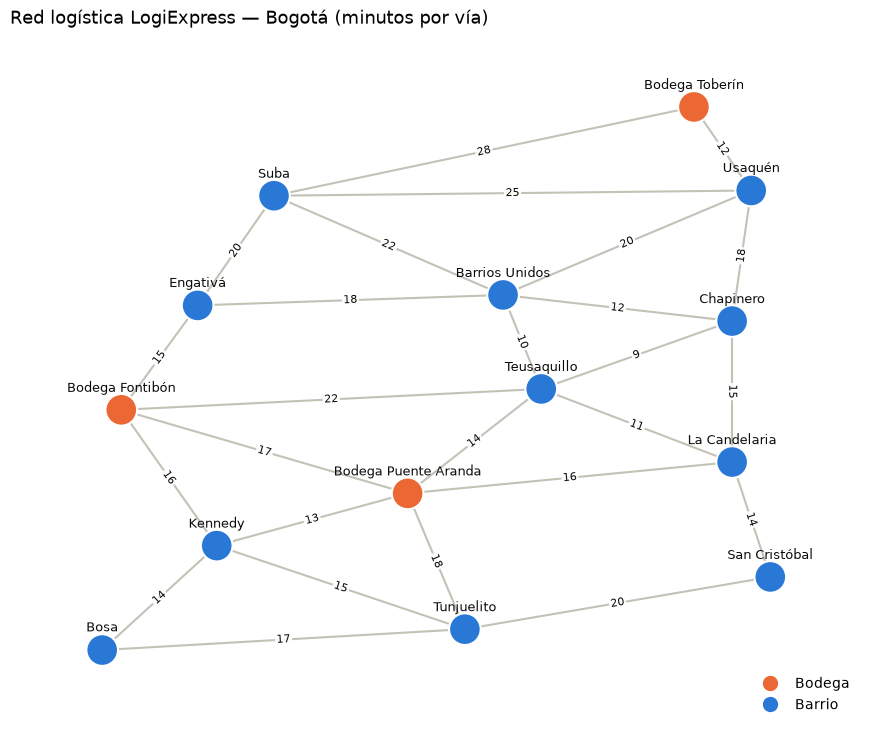

In [28]:
dibujar_grafo(red, POSICIONES)

### 8.2 Ruta más corta entre origen y destino (Dijkstra)

Caso: un paquete sale de la **Bodega Fontibón** hacia **San Cristóbal**.

Ruta recomendada: Bodega Fontibón → Bodega Puente Aranda → La Candelaria → San Cristóbal
Tiempo total:     47 min  (3 tramos)
  1. Bodega Fontibón        → Bodega Puente Aranda     17 min   (acumulado 17 min)
  2. Bodega Puente Aranda   → La Candelaria            16 min   (acumulado 33 min)
  3. La Candelaria          → San Cristóbal            14 min   (acumulado 47 min)


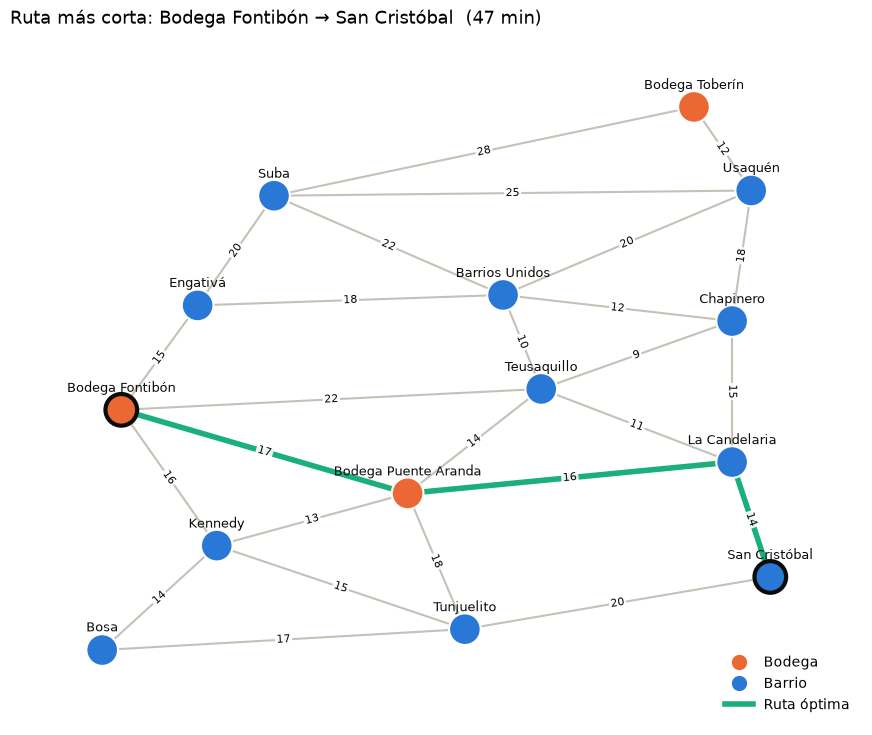

In [29]:
camino, minutos = ruta_mas_corta(red, "Bodega Fontibón", "San Cristóbal")
mostrar_ruta(red, camino, minutos)
dibujar_ruta(red, POSICIONES, camino, minutos)

### 8.3 Todas las rutas desde un origen (Dijkstra)

Un solo Dijkstra desde la **Bodega Puente Aranda** da la ruta óptima a cada ubicación. Las aristas
resaltadas forman el **árbol de rutas más cortas**.

Rutas más cortas desde: Bodega Puente Aranda

Destino                   Tiempo   Ruta
------------------------------------------------------------------------------------------
Kennedy                   13 min   Bodega Puente Aranda → Kennedy
Teusaquillo               14 min   Bodega Puente Aranda → Teusaquillo
La Candelaria             16 min   Bodega Puente Aranda → La Candelaria
Bodega Fontibón           17 min   Bodega Puente Aranda → Bodega Fontibón
Tunjuelito                18 min   Bodega Puente Aranda → Tunjuelito
Chapinero                 23 min   Bodega Puente Aranda → Teusaquillo → Chapinero
Barrios Unidos            24 min   Bodega Puente Aranda → Teusaquillo → Barrios Unidos
Bosa                      27 min   Bodega Puente Aranda → Kennedy → Bosa
San Cristóbal             30 min   Bodega Puente Aranda → La Candelaria → San Cristóbal
Engativá                  32 min   Bodega Puente Aranda → Bodega Fontibón → Engativá
Usaquén                   41 min   Bodega Puente Aranda →

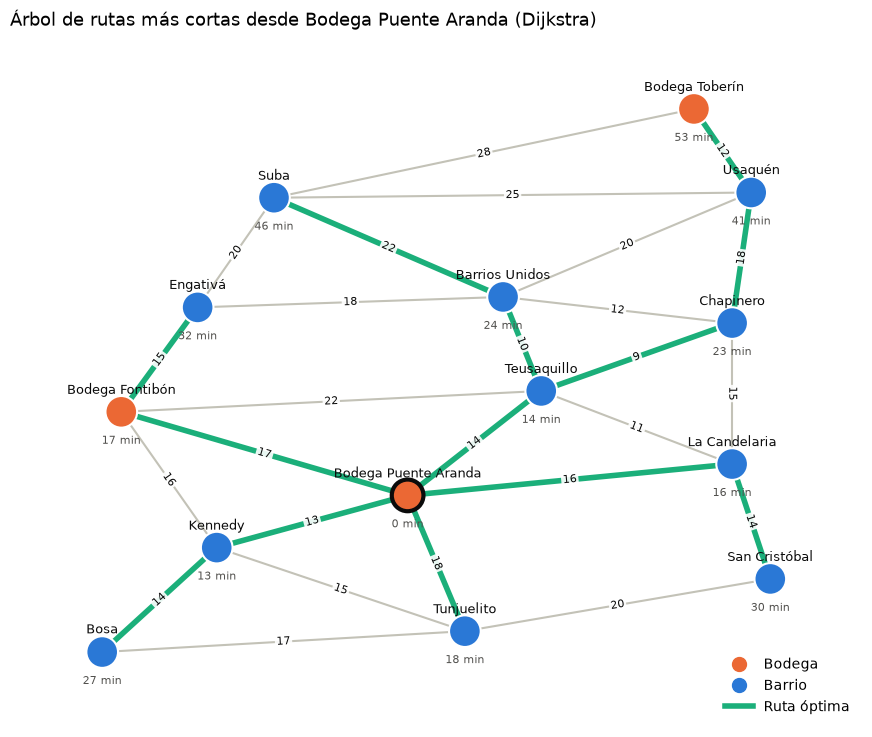

In [30]:
mostrar_tabla_desde_origen("Bodega Puente Aranda", rutas_desde_origen(red, "Bodega Puente Aranda"))
dibujar_arbol_rutas(red, POSICIONES, "Bodega Puente Aranda")

### 8.4 Rutas entre todos los pares (Floyd-Warshall)

             B.Font B.P.Ar B.Tobe   Suba Usaqué Engati B.Unid Chapin Teusaq Candel Kenned   Bosa Tunjue S.Cris
B.Fontibón        0     17     61     35     49     15     32     31     22     33     16     30     31     47
B.P.Aranda       17      0     53     46     41     32     24     23     14     16     13     27     18     30
B.Toberín        61     53      0     28     12     48     32     30     39     45     66     80     71     59
Suba             35     46     28      0     25     20     22     34     32     43     51     65     64     57
Usaquén          49     41     12     25      0     38     20     18     27     33     54     68     59     47
Engativá         15     32     48     20     38      0     18     30     28     39     31     45     46     53
B.Unidos         32     24     32     22     20     18      0     12     10     21     37     51     42     35
Chapinero        31     23     30     34     18     30     12      0      9     15     36     50     41     29
T

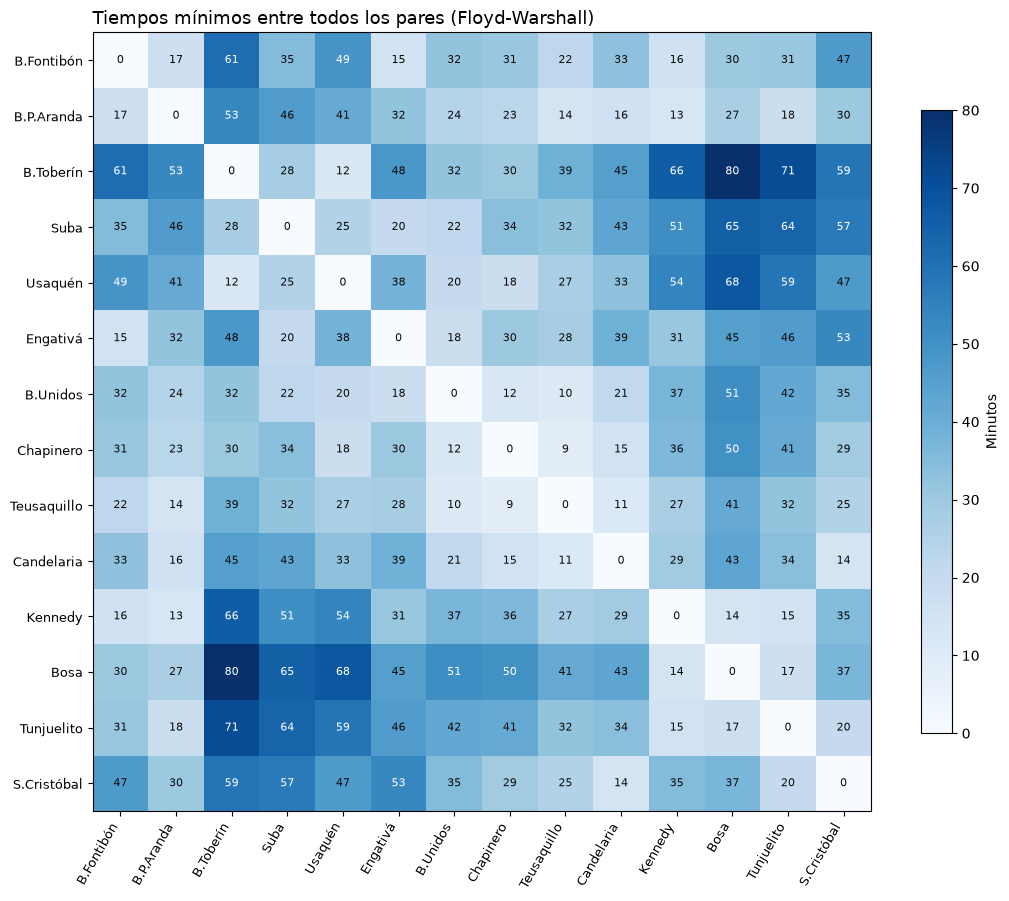

In [31]:
distancias_fw, siguiente_fw = floyd_warshall(red)
mostrar_matriz_distancias(red, distancias_fw)
dibujar_matriz_calor(red, distancias_fw)

In [32]:
# Reconstrucción de un camino con la matriz `siguiente`
camino = reconstruir_camino_floyd(siguiente_fw, "Suba", "Tunjuelito")
mostrar_ruta(red, camino, distancias_fw["Suba"]["Tunjuelito"])

Ruta recomendada: Suba → Barrios Unidos → Teusaquillo → Bodega Puente Aranda → Tunjuelito
Tiempo total:     64 min  (4 tramos)
  1. Suba                   → Barrios Unidos           22 min   (acumulado 22 min)
  2. Barrios Unidos         → Teusaquillo              10 min   (acumulado 32 min)
  3. Teusaquillo            → Bodega Puente Aranda     14 min   (acumulado 46 min)
  4. Bodega Puente Aranda   → Tunjuelito               18 min   (acumulado 64 min)


### 8.5 Recomendación de bodega de despacho

In [33]:
for bodega, tiempo in recomendar_bodega(red, "Chapinero", distancias_fw):
    print(f"{bodega:<22} {formatear_minutos(tiempo)}")

Bodega Puente Aranda   23 min
Bodega Toberín         30 min
Bodega Fontibón        31 min


### 8.6 Verificación: Dijkstra y Floyd-Warshall coinciden

Ejecutando Dijkstra desde cada origen se debe obtener exactamente la misma matriz que con
Floyd-Warshall. Es una prueba cruzada de que ambas implementaciones son correctas.

In [34]:
def verificar_consistencia(grafo):
    """Compara Dijkstra (desde cada nodo) con Floyd-Warshall. True si todas las distancias coinciden."""
    distancias_fw, _ = floyd_warshall(grafo)
    diferencias = [
        (origen, destino)
        for origen in grafo.ubicaciones()
        for destino, valor in dijkstra(grafo, origen)[0].items()
        if valor != distancias_fw[origen][destino]
    ]
    for origen, destino in diferencias:
        print(f"  Diferencia en {origen} → {destino}")
    return not diferencias


pares = len(red) ** 2
print(f"Pares comparados: {pares}")
print("✓ Ambos algoritmos coinciden." if verificar_consistencia(red) else "✗ Hay diferencias.")

Pares comparados: 196
✓ Ambos algoritmos coinciden.


### 8.7 Manejo de entradas inválidas

In [35]:
# 1. Ubicación inexistente
try:
    ruta_mas_corta(red, "Bodega Fontibón", "Medellín")
except KeyError as error:
    print("Ubicación inexistente →", error.args[0])

# 2. Peso negativo
try:
    red.agregar_ruta("Suba", "Kennedy", -5)
except ValueError as error:
    print("Peso negativo        →", error)

# 3. Sin ruta posible: ubicación nueva sin conexiones (en una copia de la red)
red_prueba, _ = crear_red_bogota()
red_prueba.agregar_ubicacion("Sumapaz")
try:
    ruta_mas_corta(red_prueba, "Bodega Fontibón", "Sumapaz")
except ValueError as error:
    print("Sin ruta posible     →", error)

Ubicación inexistente → La ubicación 'Medellín' no existe en la red.
Peso negativo        → Peso negativo no permitido (-5). Los tiempos de viaje deben ser >= 0.
Sin ruta posible     → No existe ninguna ruta entre 'Bodega Fontibón' y 'Sumapaz'.


### 8.8 Menú interactivo

Ejecute la siguiente celda para usar el sistema desde la consola. Escriba `0` para salir.


  LogiExpress — Gestión de rutas de entrega
  1. Ver la red de ubicaciones
  2. Ruta más corta entre origen y destino (Dijkstra)
  3. Rutas más cortas desde un origen (Dijkstra)
  4. Rutas entre todos los pares (Floyd-Warshall)
  5. Recomendar bodega de despacho para un pedido
  0. Salir

Grafo(no dirigido, 14 ubicaciones, 26 rutas)
   1. Bodega Fontibón (bodega)
   2. Bodega Puente Aranda (bodega)
   3. Bodega Toberín (bodega)
   4. Suba
   5. Usaquén
   6. Engativá
   7. Barrios Unidos
   8. Chapinero
   9. Teusaquillo
  10. La Candelaria
  11. Kennedy
  12. Bosa
  13. Tunjuelito
  14. San Cristóbal


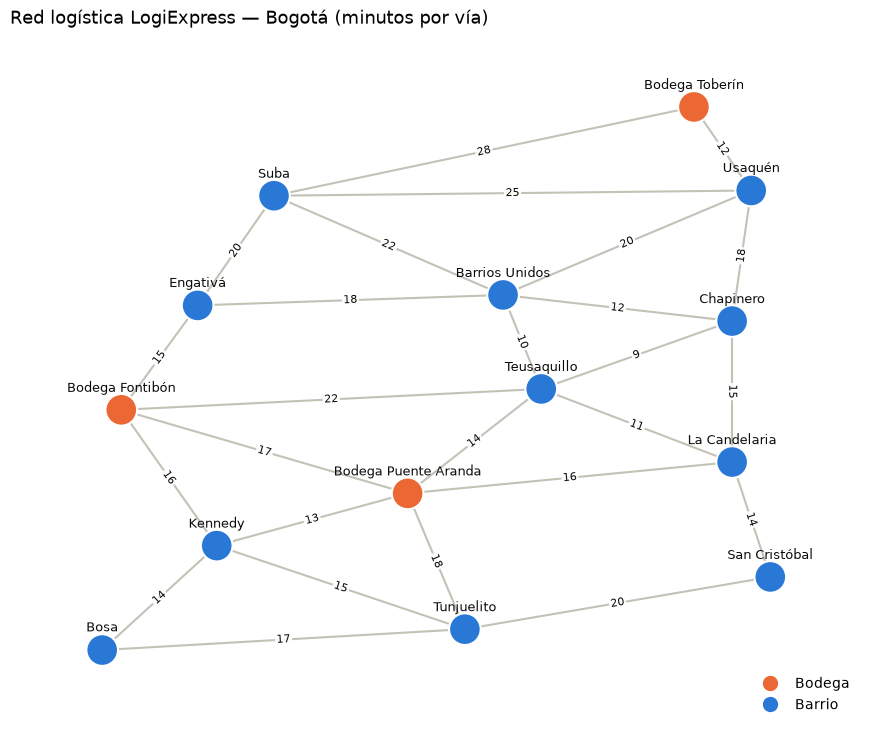


  LogiExpress — Gestión de rutas de entrega
  1. Ver la red de ubicaciones
  2. Ruta más corta entre origen y destino (Dijkstra)
  3. Rutas más cortas desde un origen (Dijkstra)
  4. Rutas entre todos los pares (Floyd-Warshall)
  5. Recomendar bodega de despacho para un pedido
  0. Salir

   1. Bodega Fontibón (bodega)
   2. Bodega Puente Aranda (bodega)
   3. Bodega Toberín (bodega)
   4. Suba
   5. Usaquén
   6. Engativá
   7. Barrios Unidos
   8. Chapinero
   9. Teusaquillo
  10. La Candelaria
  11. Kennedy
  12. Bosa
  13. Tunjuelito
  14. San Cristóbal
Ruta recomendada: San Cristóbal → La Candelaria → Teusaquillo → Barrios Unidos → Engativá
Tiempo total:     53 min  (4 tramos)
  1. San Cristóbal          → La Candelaria            14 min   (acumulado 14 min)
  2. La Candelaria          → Teusaquillo              11 min   (acumulado 25 min)
  3. Teusaquillo            → Barrios Unidos           10 min   (acumulado 35 min)
  4. Barrios Unidos         → Engativá                 18 m

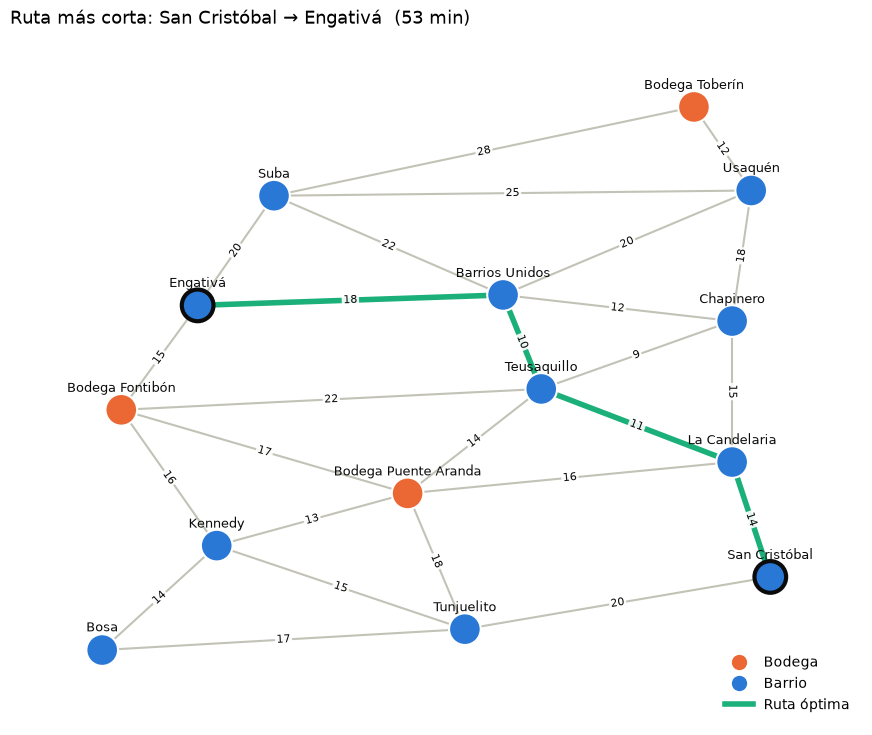


  LogiExpress — Gestión de rutas de entrega
  1. Ver la red de ubicaciones
  2. Ruta más corta entre origen y destino (Dijkstra)
  3. Rutas más cortas desde un origen (Dijkstra)
  4. Rutas entre todos los pares (Floyd-Warshall)
  5. Recomendar bodega de despacho para un pedido
  0. Salir

   1. Bodega Fontibón (bodega)
   2. Bodega Puente Aranda (bodega)
   3. Bodega Toberín (bodega)
   4. Suba
   5. Usaquén
   6. Engativá
   7. Barrios Unidos
   8. Chapinero
   9. Teusaquillo
  10. La Candelaria
  11. Kennedy
  12. Bosa
  13. Tunjuelito
  14. San Cristóbal
Rutas más cortas desde: Barrios Unidos

Destino                   Tiempo   Ruta
------------------------------------------------------------------------------------------
Teusaquillo               10 min   Barrios Unidos → Teusaquillo
Chapinero                 12 min   Barrios Unidos → Chapinero
Engativá                  18 min   Barrios Unidos → Engativá
Usaquén                   20 min   Barrios Unidos → Usaquén
La Candelaria    

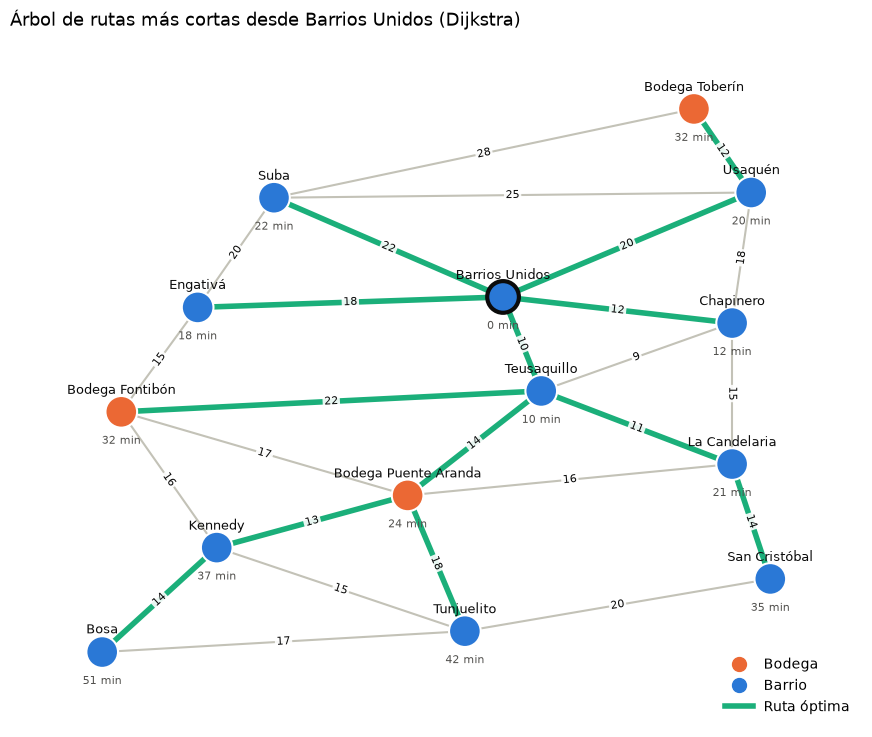


  LogiExpress — Gestión de rutas de entrega
  1. Ver la red de ubicaciones
  2. Ruta más corta entre origen y destino (Dijkstra)
  3. Rutas más cortas desde un origen (Dijkstra)
  4. Rutas entre todos los pares (Floyd-Warshall)
  5. Recomendar bodega de despacho para un pedido
  0. Salir

             B.Font B.P.Ar B.Tobe   Suba Usaqué Engati B.Unid Chapin Teusaq Candel Kenned   Bosa Tunjue S.Cris
B.Fontibón        0     17     61     35     49     15     32     31     22     33     16     30     31     47
B.P.Aranda       17      0     53     46     41     32     24     23     14     16     13     27     18     30
B.Toberín        61     53      0     28     12     48     32     30     39     45     66     80     71     59
Suba             35     46     28      0     25     20     22     34     32     43     51     65     64     57
Usaquén          49     41     12     25      0     38     20     18     27     33     54     68     59     47
Engativá         15     32     48     20   

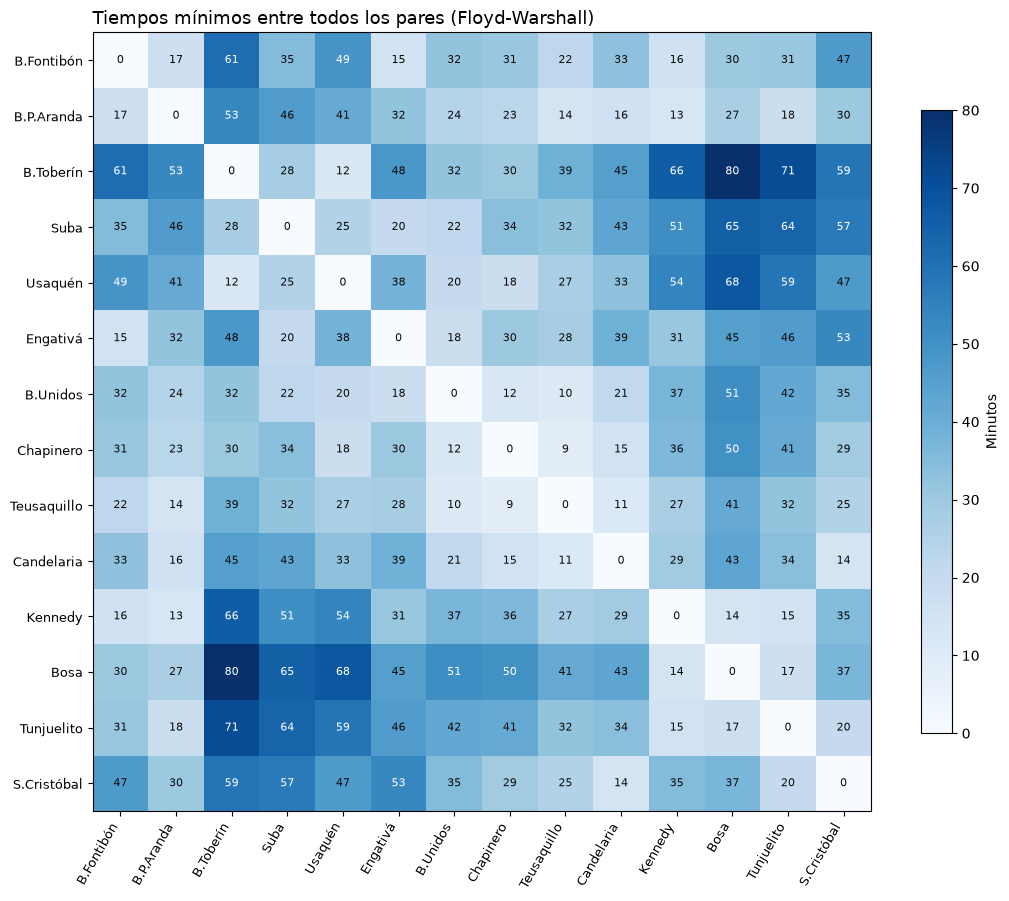

Ruta recomendada: Bodega Toberín → Usaquén → Chapinero → Teusaquillo → Bodega Puente Aranda → Kennedy → Bosa
Tiempo total:     80 min  (6 tramos)
  1. Bodega Toberín         → Usaquén                  12 min   (acumulado 12 min)
  2. Usaquén                → Chapinero                18 min   (acumulado 30 min)
  3. Chapinero              → Teusaquillo               9 min   (acumulado 39 min)
  4. Teusaquillo            → Bodega Puente Aranda     14 min   (acumulado 53 min)
  5. Bodega Puente Aranda   → Kennedy                  13 min   (acumulado 66 min)
  6. Kennedy                → Bosa                     14 min   (acumulado 80 min)

  LogiExpress — Gestión de rutas de entrega
  1. Ver la red de ubicaciones
  2. Ruta más corta entre origen y destino (Dijkstra)
  3. Rutas más cortas desde un origen (Dijkstra)
  4. Rutas entre todos los pares (Floyd-Warshall)
  5. Recomendar bodega de despacho para un pedido
  0. Salir

   1. Bodega Fontibón (bodega)
   2. Bodega Puente Aranda (bodega

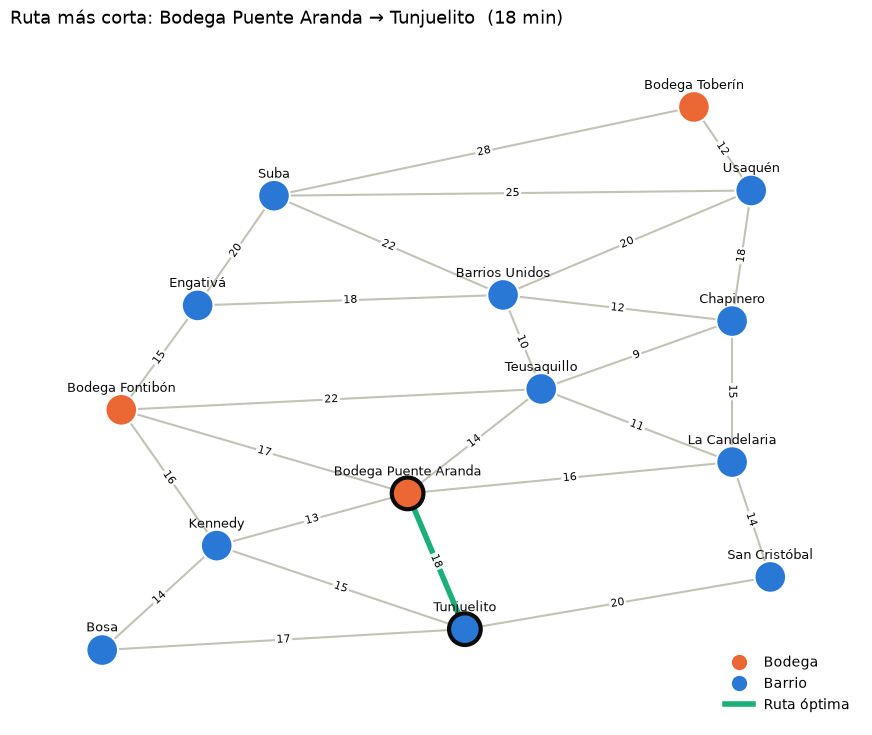


  LogiExpress — Gestión de rutas de entrega
  1. Ver la red de ubicaciones
  2. Ruta más corta entre origen y destino (Dijkstra)
  3. Rutas más cortas desde un origen (Dijkstra)
  4. Rutas entre todos los pares (Floyd-Warshall)
  5. Recomendar bodega de despacho para un pedido
  0. Salir

             B.Font B.P.Ar B.Tobe   Suba Usaqué Engati B.Unid Chapin Teusaq Candel Kenned   Bosa Tunjue S.Cris
B.Fontibón        0     17     61     35     49     15     32     31     22     33     16     30     31     47
B.P.Aranda       17      0     53     46     41     32     24     23     14     16     13     27     18     30
B.Toberín        61     53      0     28     12     48     32     30     39     45     66     80     71     59
Suba             35     46     28      0     25     20     22     34     32     43     51     65     64     57
Usaquén          49     41     12     25      0     38     20     18     27     33     54     68     59     47
Engativá         15     32     48     20   

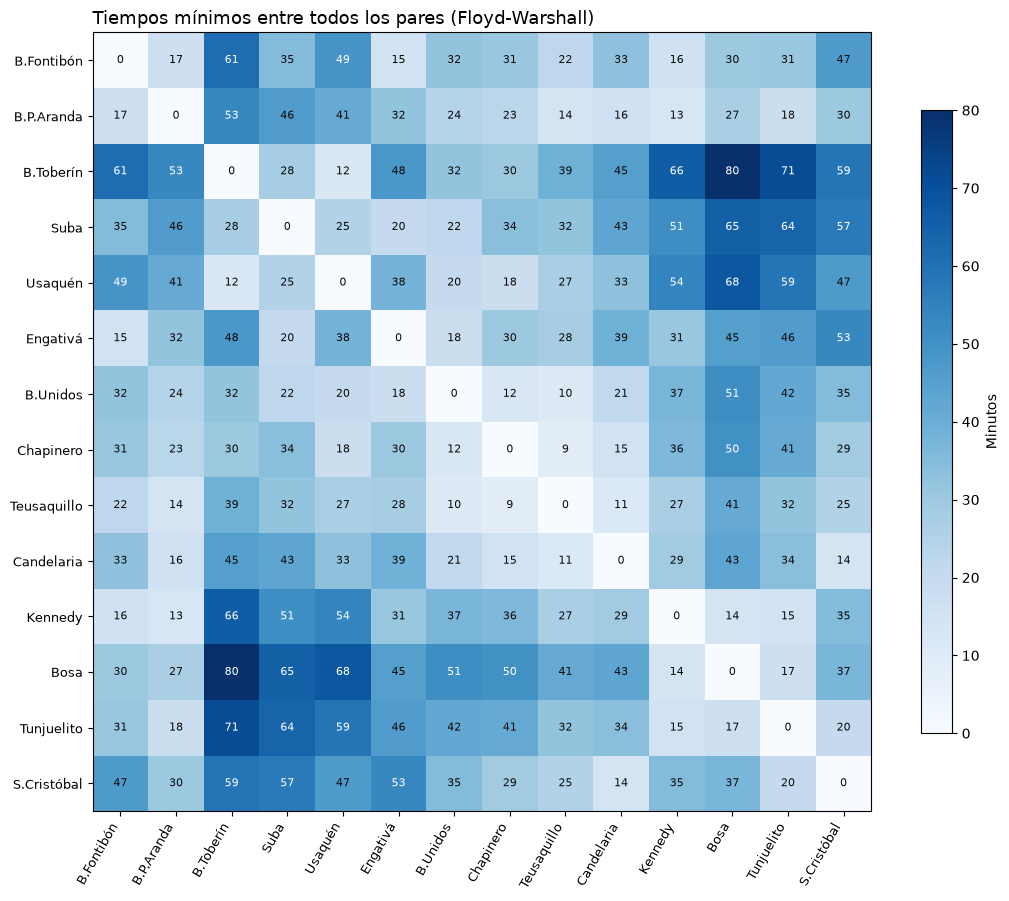


  LogiExpress — Gestión de rutas de entrega
  1. Ver la red de ubicaciones
  2. Ruta más corta entre origen y destino (Dijkstra)
  3. Rutas más cortas desde un origen (Dijkstra)
  4. Rutas entre todos los pares (Floyd-Warshall)
  5. Recomendar bodega de despacho para un pedido
  0. Salir

   1. Bodega Fontibón (bodega)
   2. Bodega Puente Aranda (bodega)
   3. Bodega Toberín (bodega)
   4. Suba
   5. Usaquén
   6. Engativá
   7. Barrios Unidos
   8. Chapinero
   9. Teusaquillo
  10. La Candelaria
  11. Kennedy
  12. Bosa
  13. Tunjuelito
  14. San Cristóbal
Bodegas ordenadas por tiempo hasta Chapinero:
  - Bodega Puente Aranda   23 min
  - Bodega Toberín         30 min
  - Bodega Fontibón        31 min

★ Recomendación: despachar desde Bodega Puente Aranda.

Ruta recomendada: Bodega Puente Aranda → Teusaquillo → Chapinero
Tiempo total:     23 min  (2 tramos)
  1. Bodega Puente Aranda   → Teusaquillo              14 min   (acumulado 14 min)
  2. Teusaquillo            → Chapinero      

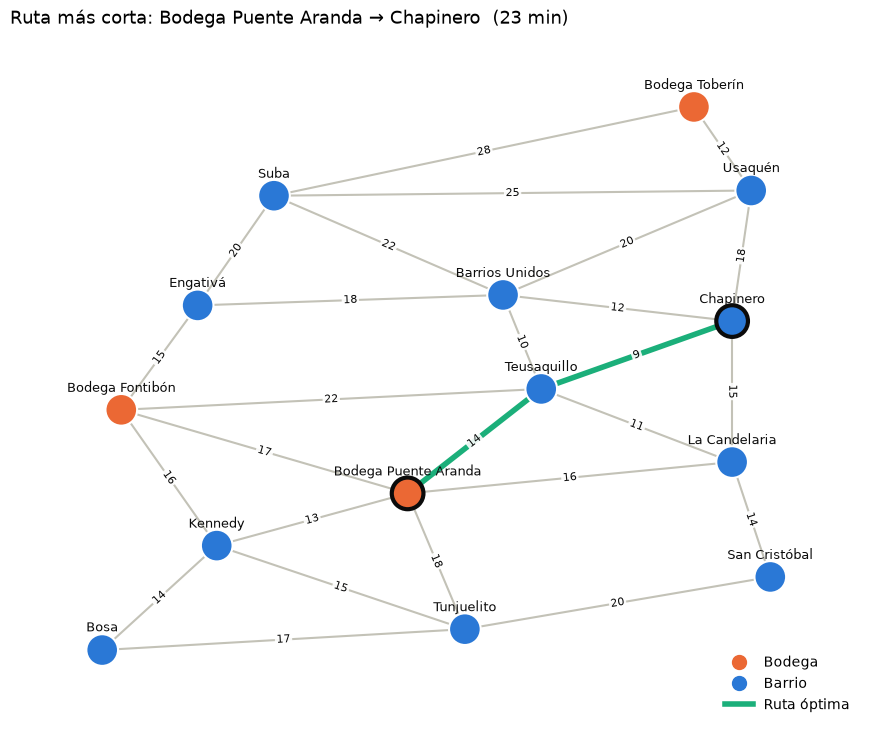


  LogiExpress — Gestión de rutas de entrega
  1. Ver la red de ubicaciones
  2. Ruta más corta entre origen y destino (Dijkstra)
  3. Rutas más cortas desde un origen (Dijkstra)
  4. Rutas entre todos los pares (Floyd-Warshall)
  5. Recomendar bodega de despacho para un pedido
  0. Salir
¡Hasta pronto!


In [36]:
menu_principal(red, POSICIONES)

## Conclusiones

- La **lista de adyacencia** es la representación adecuada para una red vial dispersa: O(V + E) de memoria.
- **Dijkstra** resuelve eficientemente el caso más común (un vehículo que sale de una bodega):
  O((V + E) log V) y, con un solo cálculo, da las rutas a todos los destinos.
- **Floyd-Warshall** precalcula en O(V³) la tabla completa de tiempos, útil para consultas
  repetidas como elegir la bodega de despacho en O(B).
- Ambos algoritmos producen los mismos resultados (sección 8.6), lo que valida las implementaciones.